## Step 1: Setup
Imports, seed, device, and a quick look at the dataset folders.

In [15]:
import os
import random
import time
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, models, transforms
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch:", torch.__version__, "| device:", device)
if device.type == "cuda":
    print("gpu:", torch.cuda.get_device_name(0))


def find_data_root(base):
    for root, dirs, _ in os.walk(base):
        if {"train", "val", "test"} <= set(dirs):
            return root
    raise FileNotFoundError(f"no folder with train/val/test found under {base}")


DATA_DIR = find_data_root("/kaggle/input/datasets/xxxguruji/data-1")
print("data dir:", DATA_DIR)
for split in ["train", "val", "test"]:
    classes = sorted(os.listdir(f"{DATA_DIR}/{split}"))
    n_images = sum(len(os.listdir(f"{DATA_DIR}/{split}/{c}")) for c in classes)
    print(f"{split}: {len(classes)} classes, {n_images} images")

torch: 2.11.0+cu130 | device: cuda
gpu: Tesla T4
data dir: /kaggle/input/datasets/xxxguruji/data-1
train: 60 classes, 1996 images
val: 60 classes, 296 images
test: 60 classes, 1889 images


In [16]:
IMG_SIZE = 224
BATCH_SIZE = 32
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

train_tf = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.5, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.TrivialAugmentWide(),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
    transforms.RandomErasing(p=0.1),
])

eval_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

train_ds = datasets.ImageFolder(f"{DATA_DIR}/train", transform=train_tf)
val_ds = datasets.ImageFolder(f"{DATA_DIR}/val", transform=eval_tf)
test_ds = datasets.ImageFolder(f"{DATA_DIR}/test", transform=eval_tf)

assert train_ds.classes == val_ds.classes == test_ds.classes
class_names = train_ds.classes
NUM_CLASSES = len(class_names)

loader_args = dict(batch_size=BATCH_SIZE, num_workers=4, pin_memory=True, persistent_workers=True)
train_loader = DataLoader(train_ds, shuffle=True, **loader_args)
val_loader = DataLoader(val_ds, shuffle=False, **loader_args)
test_loader = DataLoader(test_ds, shuffle=False, **loader_args)

images, labels = next(iter(train_loader))
print("classes:", NUM_CLASSES)
print("train / val / test:", len(train_ds), len(val_ds), len(test_ds))
print("batch:", images.shape)

classes: 60
train / val / test: 1996 296 1889
batch: torch.Size([32, 3, 224, 224])


In [17]:
model = models.efficientnet_b0(weights="DEFAULT", dropout=0.4, stochastic_depth_prob=0.3)
model.classifier[1] = nn.Linear(model.classifier[1].in_features, NUM_CLASSES)
model = model.to(device)

n_params = sum(p.numel() for p in model.parameters())
print("parameters:", f"{n_params:,}")
print("output shape:", model(images.to(device)).shape)

parameters: 4,084,408
output shape: torch.Size([32, 60])


In [20]:
EPOCHS = 100
PATIENCE = 20
WARMUP_EPOCHS = 5
BACKBONE_LR = 3e-4
HEAD_LR = 1e-3
WEIGHT_DECAY = 1e-2
CUTMIX_PROB = 0.3

criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = torch.optim.AdamW(
    [
        {"params": model.features.parameters(), "lr": BACKBONE_LR},
        {"params": model.classifier.parameters(), "lr": HEAD_LR},
    ],
    weight_decay=WEIGHT_DECAY,
)
warmup = torch.optim.lr_scheduler.LinearLR(optimizer, start_factor=0.1, total_iters=WARMUP_EPOCHS)
plateau = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=3, min_lr=1e-6)
scaler = torch.amp.GradScaler("cuda")


def cutmix(x, y):
    lam = np.random.beta(1.0, 1.0)
    idx = torch.randperm(x.size(0), device=x.device)
    h, w = x.shape[2], x.shape[3]
    cut = np.sqrt(1 - lam)
    ch, cw = int(h * cut), int(w * cut)
    cy, cx = np.random.randint(h), np.random.randint(w)
    y1, y2 = max(cy - ch // 2, 0), min(cy + ch // 2, h)
    x1, x2 = max(cx - cw // 2, 0), min(cx + cw // 2, w)
    x[:, :, y1:y2, x1:x2] = x[idx, :, y1:y2, x1:x2]
    lam = 1 - (y2 - y1) * (x2 - x1) / (h * w)
    return x, y, y[idx], lam


def run_epoch(loader, train):
    model.train(train)
    total_loss, correct, total = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            use_cutmix = train and np.random.rand() < CUTMIX_PROB
            if use_cutmix:
                x, y_a, y_b, lam = cutmix(x, y)
            with torch.autocast(device_type="cuda"):
                out = model(x)
                if use_cutmix:
                    loss = lam * criterion(out, y_a) + (1 - lam) * criterion(out, y_b)
                else:
                    loss = criterion(out, y)
            if train:
                optimizer.zero_grad()
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
            total_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            total += x.size(0)
    return total_loss / total, correct / total


history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
best_val_loss, best_val_acc, best_epoch, wait = float("inf"), 0.0, 0, 0
start = time.time()

for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_acc = run_epoch(train_loader, train=True)
    va_loss, va_acc = run_epoch(val_loader, train=False)
    history["train_loss"].append(tr_loss)
    history["train_acc"].append(tr_acc)
    history["val_loss"].append(va_loss)
    history["val_acc"].append(va_acc)

    if epoch <= WARMUP_EPOCHS:
        warmup.step()
    else:
        plateau.step(va_loss)

    if va_loss < best_val_loss - 1e-3:
        best_val_loss, best_val_acc, best_epoch, wait = va_loss, va_acc, epoch, 0
        torch.save(model.state_dict(), "best_effnet_b0_es.pth")
        mark = " *"
    else:
        wait += 1
        mark = ""

    lr = optimizer.param_groups[0]["lr"]
    print(f"epoch {epoch:03d} | train loss {tr_loss:.3f} acc {tr_acc:.3f} | val loss {va_loss:.3f} acc {va_acc:.3f} | lr {lr:.1e}{mark}")
    if wait >= PATIENCE:
        print(f"early stopping at epoch {epoch} (no val loss improvement for {PATIENCE} epochs)")
        break

train_time = time.time() - start
print(f"\nbest epoch: {best_epoch} | val loss {best_val_loss:.3f} | val acc {best_val_acc:.3f}")
print(f"epochs run: {epoch} | training time: {train_time / 60:.1f} min")

epoch 001 | train loss 1.141 acc 0.890 | val loss 1.157 acc 0.868 | lr 8.4e-05 *
epoch 002 | train loss 1.095 acc 0.933 | val loss 1.111 acc 0.895 | lr 1.4e-04 *
epoch 003 | train loss 1.194 acc 0.908 | val loss 1.102 acc 0.899 | lr 1.9e-04 *
epoch 004 | train loss 1.120 acc 0.883 | val loss 1.098 acc 0.878 | lr 2.5e-04 *
epoch 005 | train loss 1.102 acc 0.928 | val loss 1.064 acc 0.902 | lr 3.0e-04 *
epoch 006 | train loss 1.173 acc 0.894 | val loss 1.135 acc 0.902 | lr 3.0e-04
epoch 007 | train loss 1.122 acc 0.892 | val loss 1.149 acc 0.865 | lr 3.0e-04
epoch 008 | train loss 1.070 acc 0.922 | val loss 1.136 acc 0.889 | lr 3.0e-04
epoch 009 | train loss 1.059 acc 0.931 | val loss 1.114 acc 0.899 | lr 3.0e-04
epoch 010 | train loss 1.152 acc 0.910 | val loss 1.120 acc 0.889 | lr 3.0e-04
epoch 011 | train loss 1.044 acc 0.912 | val loss 1.127 acc 0.892 | lr 3.0e-04
epoch 012 | train loss 1.183 acc 0.882 | val loss 1.150 acc 0.895 | lr 3.0e-04
epoch 013 | train loss 1.150 acc 0.901 | v

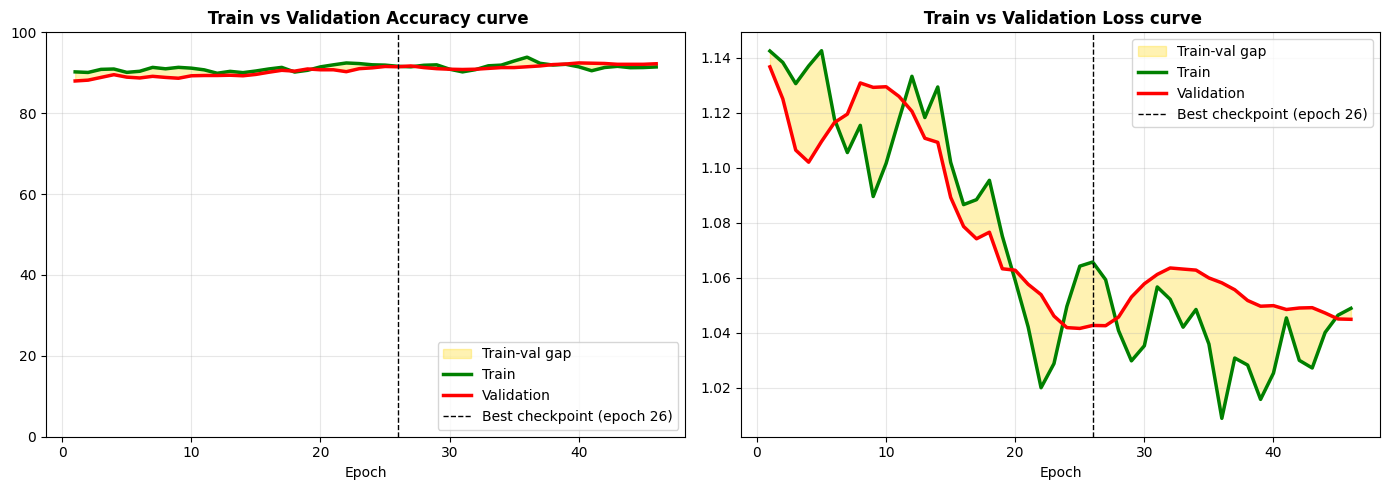

train acc: 1.000
val acc:   0.922
test acc:  0.866


In [26]:
def smooth(values, k=5):
    padded = np.pad(values, (k // 2, k // 2), mode="edge")
    return np.convolve(padded, np.ones(k) / k, mode="valid")


epochs = np.arange(1, len(history["train_acc"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, key, title in [(axes[0], "acc", ""), (axes[1], "loss", " Train vs Validation Loss curve")]:
    scale = 100 if key == "acc" else 1
    tr = np.array(history[f"train_{key}"]) * scale
    va = np.array(history[f"val_{key}"]) * scale
    tr_s, va_s = smooth(tr), smooth(va)
    ax.fill_between(epochs, tr_s, va_s, color="gold", alpha=0.3, label="Train-val gap")
    ax.plot(epochs, tr_s, color="green", lw=2.5, label="Train")
    ax.plot(epochs, va_s, color="red", lw=2.5, label="Validation")
    ax.axvline(best_epoch, color="black", ls="--", lw=1, label=f"Best checkpoint (epoch {best_epoch})")
    if key == "acc":
        ax.set_ylim(0, 100)
        ax.set_title(f"{title} Train vs Validation Accuracy curve", fontweight="bold")
        ax.legend(loc="lower right")
    else:
        ax.set_title(title, fontweight="bold")
        ax.legend(loc="upper right")
    ax.set_xlabel("Epoch")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("curves_effnet.png", dpi=200)
plt.show()

train_clean_ds = datasets.ImageFolder(f"{DATA_DIR}/train", transform=eval_tf)
train_clean_loader = DataLoader(train_clean_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

model.load_state_dict(torch.load("best_effnet_b0_es.pth"))
model.eval()


def evaluate(loader):
    preds, targets = [], []
    with torch.no_grad():
        for x, y in loader:
            out = model(x.to(device))
            preds.append(out.argmax(1).cpu())
            targets.append(y)
    preds, targets = torch.cat(preds), torch.cat(targets)
    return (preds == targets).float().mean().item(), preds, targets


train_acc, _, _ = evaluate(train_clean_loader)
val_acc, _, _ = evaluate(val_loader)
test_acc, _, _ = evaluate(test_loader)
print(f"train acc: {train_acc:.3f}")
print(f"val acc:   {val_acc:.3f}")
print(f"test acc:  {test_acc:.3f}")

test accuracy: 0.8655
test macro F1: 0.8877  
                                           precision  recall     f1  support
00_Golden-Delicious                            0.650   0.578  0.612       45
01_Granny-Smith                                0.646   0.879  0.745       58
02_Pink-Lady                                   0.728   1.000  0.843       59
03_Royal-Gala                                  1.000   0.719  0.836       64
04_Avocado                                     0.973   0.900  0.935       40
05_Banana                                      0.936   1.000  0.967       44
06_Kiwi                                        0.891   0.911  0.901       45
07_Lemon                                       0.629   0.537  0.579       41
08_Lime                                        0.781   0.833  0.806       30
09_Mango                                       0.947   0.581  0.720       31
10_Cantaloupe                                  1.000   0.692  0.818       39
11_Galia-Melon                

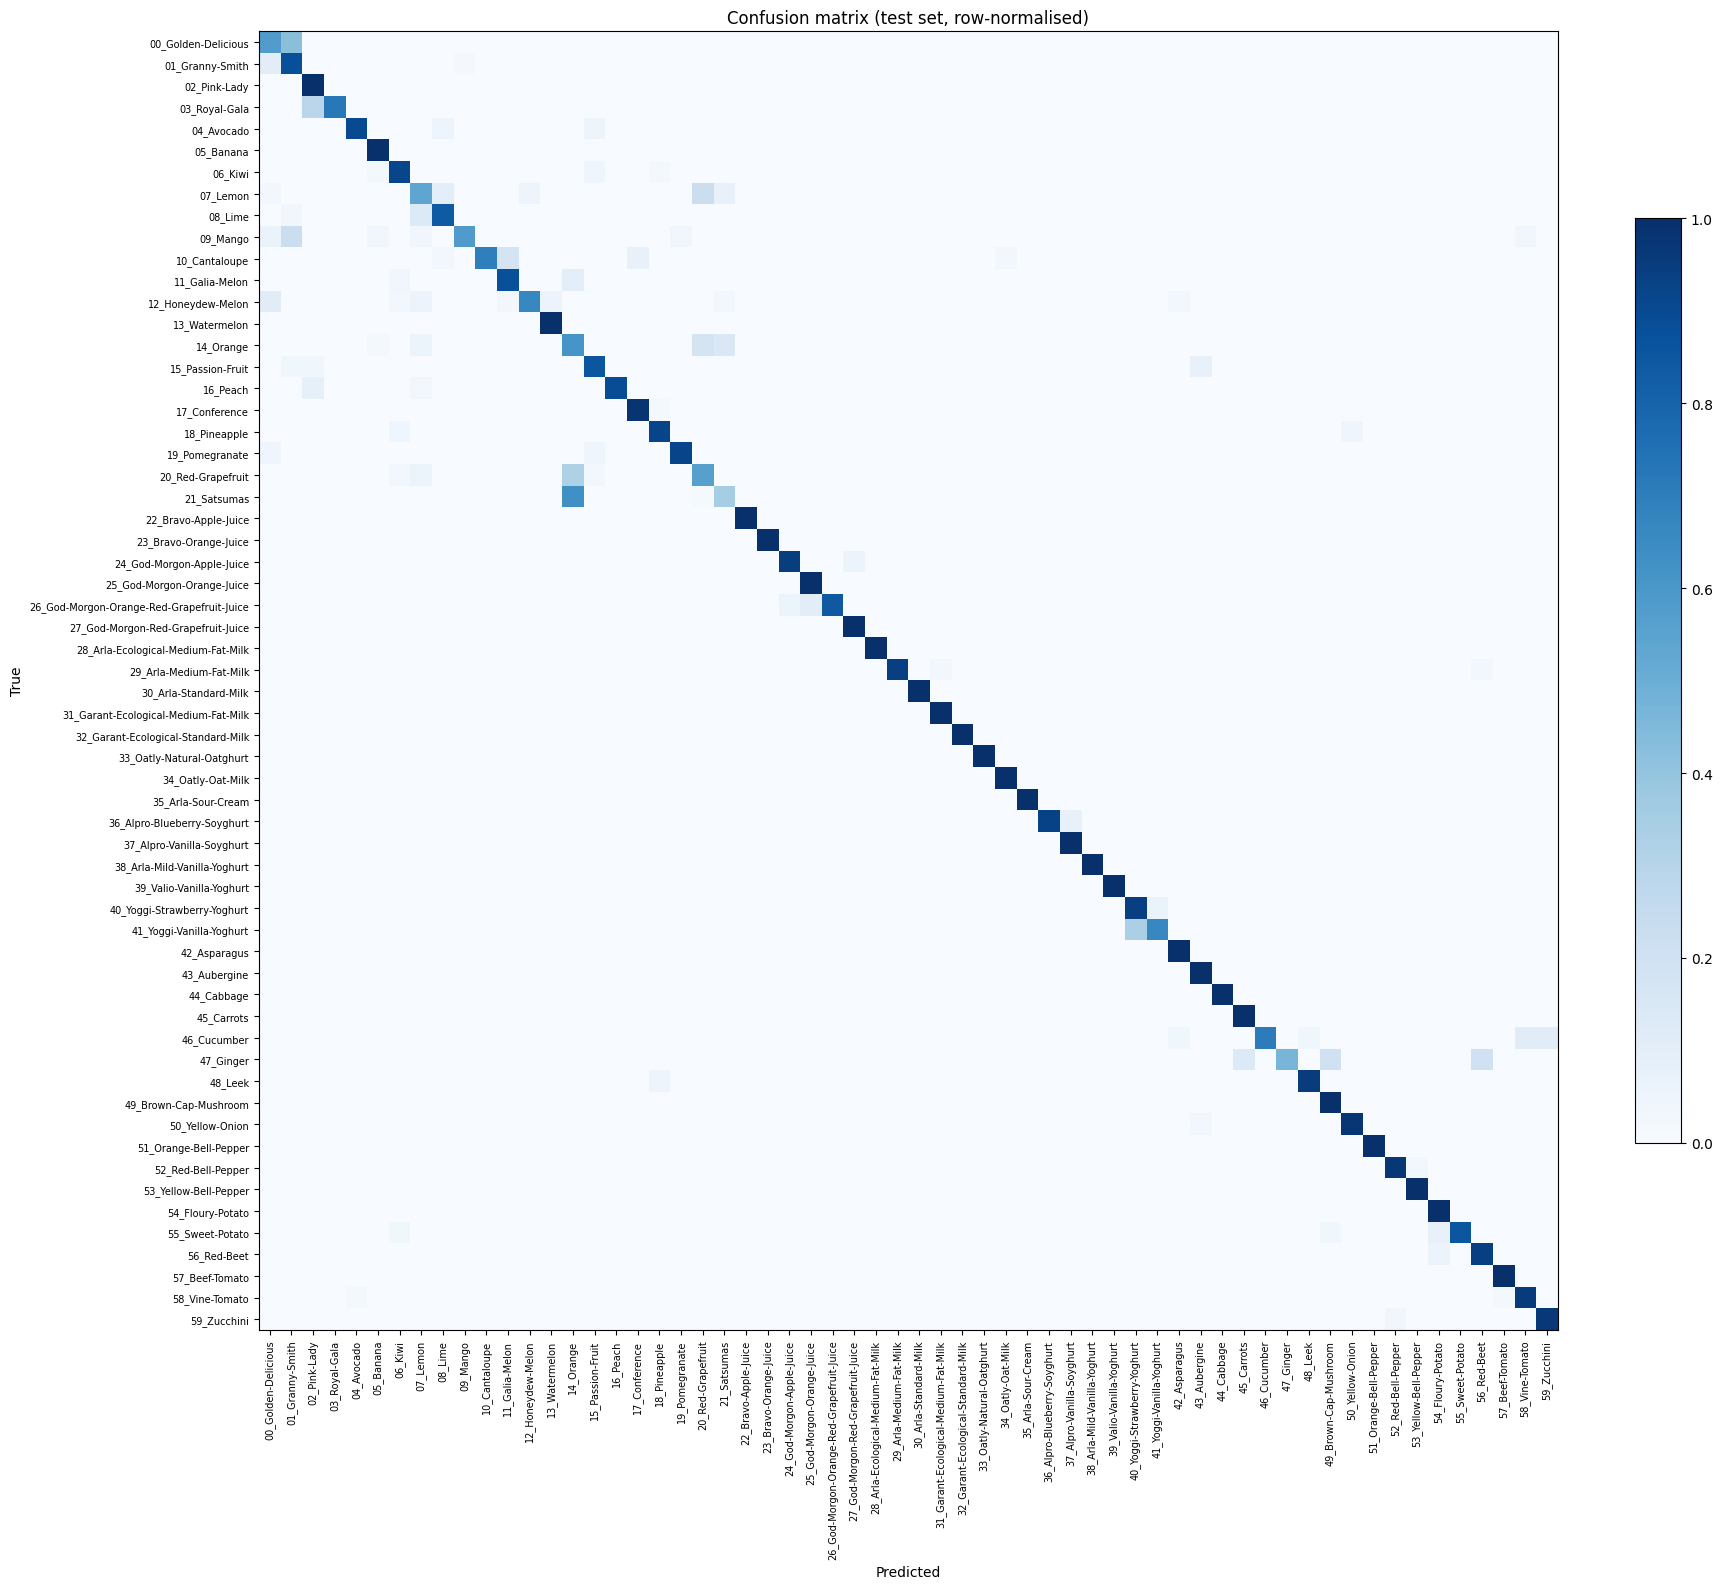


Most confused pairs (true -> predicted, count):
  21_Satsumas -> 14_Orange: 43
  00_Golden-Delicious -> 01_Granny-Smith: 19
  03_Royal-Gala -> 02_Pink-Lady: 18
  20_Red-Grapefruit -> 14_Orange: 11
  14_Orange -> 20_Red-Grapefruit: 10
  07_Lemon -> 20_Red-Grapefruit: 9
  14_Orange -> 21_Satsumas: 8
  10_Cantaloupe -> 11_Galia-Melon: 7
  09_Mango -> 01_Granny-Smith: 7
  01_Granny-Smith -> 00_Golden-Delicious: 6


In [30]:
import pandas as pd
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score

_, preds, targets = evaluate(test_loader)
y_pred, y_true = preds.numpy(), targets.numpy()

test_acc = accuracy_score(y_true, y_pred)
macro_f1 = f1_score(y_true, y_pred, average="macro", zero_division=0)
print(f"test accuracy: {test_acc:.4f}")
print(f"test macro F1: {macro_f1:.4f}  ")

report = classification_report(y_true, y_pred, target_names=class_names, output_dict=True, zero_division=0)
per_class = pd.DataFrame(report).T.iloc[:NUM_CLASSES].round(3)
per_class.columns = ["precision", "recall", "f1", "support"]
per_class["support"] = per_class["support"].astype(int)
per_class.to_csv("per_class_report_effnet.csv")
pd.set_option("display.max_rows", None)
print(per_class)

cm = confusion_matrix(y_true, y_pred)
np.savetxt("confusion_matrix_effnet.csv", cm, fmt="%d", delimiter=",")
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(18, 16))
im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(NUM_CLASSES))
ax.set_yticks(range(NUM_CLASSES))
ax.set_xticklabels(class_names, rotation=90, fontsize=7)
ax.set_yticklabels(class_names, fontsize=7)
ax.set_xlabel("Predicted")
ax.set_ylabel("True")
ax.set_title("Confusion matrix (test set, row-normalised)")
fig.colorbar(im, fraction=0.03)
plt.tight_layout()
plt.savefig("confusion_matrix_effnet.png", dpi=200)
plt.show()

off_diag = cm.copy()
np.fill_diagonal(off_diag, 0)
print("\nMost confused pairs (true -> predicted, count):")
for flat in np.argsort(off_diag, axis=None)[::-1][:10]:
    i, j = divmod(flat, NUM_CLASSES)
    print(f"  {class_names[i]} -> {class_names[j]}: {off_diag[i, j]}")

In [29]:
from PIL import Image

n_params = sum(p.numel() for p in model.parameters())
size_mb = os.path.getsize("best_effnet_b0_es.pth") / (1024 ** 2)

cpu_model = models.efficientnet_b0(weights=None)
cpu_model.classifier[1] = nn.Linear(cpu_model.classifier[1].in_features, NUM_CLASSES)
cpu_model.load_state_dict(torch.load("best_effnet_b0_es.pth", map_location="cpu"))
cpu_model.eval()

sample_path = test_ds.samples[0][0]
times = []
with torch.no_grad():
    for i in range(23):
        start_t = time.perf_counter()
        x = eval_tf(Image.open(sample_path).convert("RGB")).unsqueeze(0)
        torch.softmax(cpu_model(x), dim=1).argmax(1)
        if i >= 3:
            times.append((time.perf_counter() - start_t) * 1000)

print(f"parameters:      {n_params:,}")
print(f"model file size: {size_mb:.1f} MB   ")
print(f"median CPU time: {np.median(times):.1f} ms   ")
print(f"training time:   {train_time / 60:.1f} min")

parameters:      4,084,408
model file size: 15.9 MB   
median CPU time: 40.3 ms   
training time:   5.7 min
